# Pad → load calibration with coins (13 Nov 2026)

**Question.** How does the FlexiTac pad signal relate to load, and where (if anywhere) does it saturate?

**Setup.** Left pad on the X6 finger, facing up and level. 10-yen coins (4.5 g, 23.5 mm), no plate,
0 → 45 g → 0 in 4.5 g steps (~5 s each), 3 repeats without re-zeroing between them.
`coin_marker.py` published the load on `/calib_load_g`, recorded in the same bag as both pads.

**Bags.** `coins_rep1`, `coins_rep2`, `coins_rep3`.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
sys.path.insert(0, str(Path.cwd()))             # flexigrasp_bag.py sits next to this notebook
import flexigrasp_bag as fb

COIN_DIR = Path(os.environ.get("COIN_DIR", "~/coins")).expanduser()   # folder holding coins_rep1..3
LOADED_PAD = "left"
REPEATS = [1, 2, 3]
bags = {r: next((COIN_DIR / f"coins_rep{r}").glob("*.db3")) for r in REPEATS}
bags

{1: PosixPath('/tmp/claude-0/-home-claude/638f6bc2-14cc-56be-9ba7-925dcfe44bcd/scratchpad/coins/raw/coins_rep1/coins_rep1_0.db3'),
 2: PosixPath('/tmp/claude-0/-home-claude/638f6bc2-14cc-56be-9ba7-925dcfe44bcd/scratchpad/coins/raw/coins_rep2/coins_rep2_0.db3'),
 3: PosixPath('/tmp/claude-0/-home-claude/638f6bc2-14cc-56be-9ba7-925dcfe44bcd/scratchpad/coins/raw/coins_rep3/coins_rep3_0.db3')}

In [2]:
import matplotlib.pyplot as plt
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#1f1f1d", "#6b6b66", "#e6e6e1"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "legend.frameon": False, "figure.dpi": 110})

## 1. Load the bags

Signals per pad (see `flexigrasp_bag.py`):
- `pos`: sum of positive baseline-subtracted taxels
- `total`: the node's published total (only taxels above the contact threshold)

In [3]:
data = {}
for r, db in bags.items():
    data[r] = {s: fb.read_frames(db, s) for s in ("left", "right")}
    data[r]["load_t"], data[r]["load_g"] = fb.read_float32(db, "/calib_load_g")
    p = data[r][LOADED_PAD]
    print(f"rep{r}: {p['t'][-1]-p['t'][0]:.0f} s, {len(p['t'])/(p['t'][-1]-p['t'][0]):.1f} Hz, "
          f"max load {data[r]['load_g'].max():.1f} g")

rep1: 193 s, 93.8 Hz, max load 45.0 g


rep2: 167 s, 93.8 Hz, max load 45.0 g


rep3: 150 s, 93.9 Hz, max load 45.0 g


## 2. Steady value at each load step

Each step runs from one marker change to the next. Skip the first 1.5 s (placing the coin, settling)
and the last 0.3 s (the next coin arriving), and take the median.

In [4]:
def step_table(d, side, skip=1.5, tail=0.3):
    lt, lg = d["load_t"], d["load_g"]
    ch = list(np.flatnonzero(np.diff(lg)) + 1)
    edges = [lt[0]] + [lt[i] for i in ch] + [lt[-1]]
    loads = [lg[0]] + [lg[i] for i in ch]
    p, out = d[side], []
    for k, g in enumerate(loads):
        a, b = edges[k], edges[k + 1]
        lo, hi = (a + skip if k else a), b - tail
        if hi - lo < 1.0:
            lo = max(a + 0.8, hi - 1.0)
        m = (p["t"] >= lo) & (p["t"] <= hi)
        tt = p["t"][m]
        phase = "base" if k == 0 else ("end" if k == len(loads) - 1 else ("up" if g > loads[k - 1] else "down"))
        out.append(dict(g=float(g), phase=phase, pos=float(np.median(p["pos"][m])),
                        total=float(np.median(p["total"][m])), total_sd=float(np.std(p["total"][m])),
                        drift=float(np.polyfit(tt - tt[0], p["total"][m], 1)[0]) if m.sum() > 20 else np.nan,
                        window_s=float(hi - lo)))
    return out

steps = {r: step_table(d, LOADED_PAD) for r, d in data.items()}
for r, s in steps.items():
    print(f"rep{r}")
    for x in s:
        print(f"  {x['phase']:5s} {x['g']:5.1f} g   pos {x['pos'] - s[0]['pos']:6.0f}   "
              f"total {x['total']:5.0f} ±{x['total_sd']:4.0f}   drift {x['drift']:+6.1f}/s")

rep1
  base    0.0 g   pos      0   total     0 ±   0   drift   +0.0/s
  up      4.5 g   pos     81   total     0 ±  15   drift   +1.8/s
  up      9.0 g   pos    156   total    36 ±  17   drift   +8.4/s
  up     13.5 g   pos    401   total   102 ±  39   drift  +14.8/s
  up     18.0 g   pos    471   total   178 ±  13   drift   +4.7/s
  up     22.5 g   pos    546   total   193 ±   9   drift   -3.2/s
  up     27.0 g   pos    582   total   178 ±   9   drift   -0.3/s
  up     31.5 g   pos    608   total   167 ±  15   drift   -5.2/s
  up     36.0 g   pos    670   total   189 ±  17   drift   +7.5/s
  up     40.5 g   pos    767   total   332 ±  69   drift  +20.2/s
  up     45.0 g   pos    955   total   463 ±  39   drift   -1.5/s
  down   40.5 g   pos    843   total   411 ±  38   drift  -11.2/s
  down   36.0 g   pos    736   total   303 ±  54   drift  -21.0/s
  down   31.5 g   pos    753   total   321 ±  59   drift   -7.4/s
  down   27.0 g   pos    545   total   158 ±  75   drift   +7.3/s
  dow

## 3. Curves: loading vs unloading, all repeats

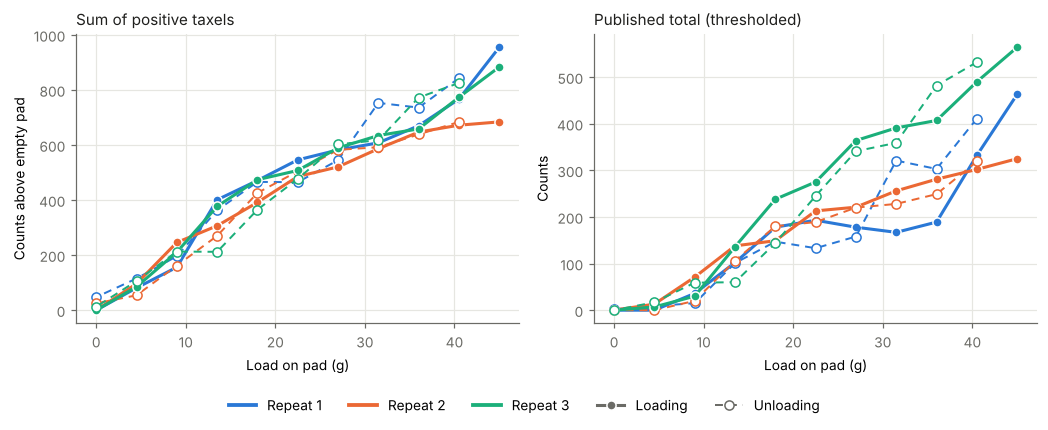

In [5]:
from matplotlib.lines import Line2D
COL = {1: BLUE, 2: ORANGE, 3: AQUA}
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.8))
for ax, key, title in ((axs[0], "pos", "Sum of positive taxels"), (axs[1], "total", "Published total (thresholded)")):
    for r, s in steps.items():
        base = s[0][key] if key == "pos" else 0
        up = [x for x in s if x["phase"] in ("base", "up")]
        dn = [x for x in s if x["phase"] in ("down", "end")]
        ax.plot([x["g"] for x in up], [x[key] - base for x in up], color=COL[r], lw=2, marker="o", ms=6, mec="white")
        ax.plot([x["g"] for x in dn], [x[key] - base for x in dn], color=COL[r], lw=1.3, ls=(0, (4, 3)),
                marker="o", ms=6, mfc="white", mec=COL[r])
    ax.set_title(title, loc="left", color=INK, fontsize=10)
    ax.set_xlabel("Load on pad (g)")
axs[0].set_ylabel("Counts above empty pad"); axs[1].set_ylabel("Counts")
handles = [Line2D([], [], color=COL[r], lw=2.5, label=f"Repeat {r}") for r in COL] + [
    Line2D([], [], color=MUTED, lw=2, marker="o", mec="white", label="Loading"),
    Line2D([], [], color=MUTED, lw=1.3, ls=(0, (4, 3)), marker="o", mfc="white", mec=MUTED, label="Unloading")]
fig.legend(handles=handles, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.03))
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig("coin_calibration.png", dpi=200, bbox_inches="tight")

## 4. Sensitivity (linear fit on loading), repeatability and hysteresis

In [6]:
fits = {}
for r, s in steps.items():
    up = [x for x in s if x["phase"] in ("base", "up")]
    g = np.array([x["g"] for x in up]); y = np.array([x["pos"] - s[0]["pos"] for x in up])
    k, c = np.polyfit(g, y, 1)
    res = y - (k * g + c)
    fits[r] = (k, c, 1 - res.var() / y.var())
    print(f"rep{r}: {k:5.1f} counts/g, intercept {c:5.0f}, R² {fits[r][2]:.3f}")
print(f"mean sensitivity: {np.mean([f[0] for f in fits.values()]):.1f} counts/g")

print("\nSpread between repeats (loading), as ± % of the mean:")
for key in ("pos", "total"):
    for g in (9.0, 18.0, 27.0, 45.0):
        v = [[x[key] - (s[0][key] if key == "pos" else 0) for x in s if x["g"] == g and x["phase"] == "up"][0]
             for s in steps.values()]
        print(f"  {key:5s} {g:4.0f} g: {np.round(v)}  ±{np.std(v) / np.mean(v) * 100:.0f}%")

print("\nUnloading vs loading, % difference (pos):")
for r, s in steps.items():
    b = s[0]["pos"]
    up = {x["g"]: x["pos"] - b for x in s if x["phase"] == "up"}
    dn = {x["g"]: x["pos"] - b for x in s if x["phase"] == "down"}
    print(f"  rep{r}:", {g: round((dn[g] - up[g]) / up[g] * 100) for g in sorted(dn)})

rep1:  19.4 counts/g, intercept    40, R² 0.954
rep2:  15.4 counts/g, intercept    75, R² 0.955
rep3:  18.5 counts/g, intercept    57, R² 0.967
mean sensitivity: 17.7 counts/g

Spread between repeats (loading), as ± % of the mean:
  pos      9 g: [156. 246. 211.]  ±18%
  pos     18 g: [471. 392. 474.]  ±9%
  pos     27 g: [582. 520. 590.]  ±5%
  pos     45 g: [955. 684. 884.]  ±14%
  total    9 g: [36. 71. 30.]  ±40%
  total   18 g: [178. 149. 238.]  ±20%
  total   27 g: [178. 221. 364.]  ±31%
  total   45 g: [463. 325. 564.]  ±22%

Unloading vs loading, % difference (pos):
  rep1: {4.5: 42, 9.0: 26, 13.5: -9, 18.0: -1, 22.5: -15, 27.0: -6, 31.5: 24, 36.0: 10, 40.5: 10}
  rep2: {4.5: -44, 9.0: -34, 13.5: -12, 18.0: 9, 22.5: 4, 27.0: 12, 31.5: 1, 36.0: -1, 40.5: 2}
  rep3: {4.5: 25, 9.0: 1, 13.5: -44, 18.0: -23, 22.5: -6, 27.0: 2, 31.5: -3, 36.0: 17, 40.5: 7}


## 5. Findings

- **No saturation up to 45 g.** The positive sum rises steadily (~17 counts/g, 15–19 across repeats,
  R² 0.95–0.97), with a slight bend above ~25 g. The earlier "flattens at ~19 g" was a dead zone at
  light loads in `total`, not saturation.
- **`total` has a dead zone:** ~0 at 4.5 g, responding from ~5–9 g. The positive sum sees 4.5 g.
- **Repeatability:** positive sum ±5–18% between repeats; `total` ±20–40% and sensitive to where the
  contact sits (rep 1 stayed flat from 18 to 36 g, then jumped when the centroid moved 2–3 taxels).
- **No consistent hysteresis:** 10–40% differences at light loads, both directions, from coin handling.
- **Settling:** readings still drift during 5 s holds (up to 20–40 counts/s). Use 8–10 s holds.
- **Zero offset after unloading:** ~10–50 counts (1–3 g). Re-zero before each grasp.

**Limits.** One pad (left), one contact size (23.5 mm disc), loads up to 45 g.
Counts per gram depend on contact area: check against the load cell between the jaws.